In [42]:
# 그래프 관련
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
# matplotlib.rcParams['font.family'] = 'AppleGothic'
matplotlib.rcParams['axes.unicode_minus']=False

import pandas as pd
import numpy as np

# 머신러닝 관련
from sklearn import svm,metrics
from sklearn.model_selection import train_test_split
from sklearn.model_selection import cross_validate
from sklearn.model_selection import StratifiedKFold
from sklearn.model_selection import GridSearchCV
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.preprocessing import StandardScaler, PolynomialFeatures, OneHotEncoder
from sklearn.metrics import mean_absolute_error 
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import plot_tree
from scipy.special import expit
from scipy.special import softmax
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import make_pipeline
import joblib

In [43]:
wine = pd.read_csv('data/wine.csv')
wine.head(2)

,alcohol,sugar,pH,class
0,9.4,1.9,3.51,0.0
1,9.8,2.6,3.20,0.0


In [44]:
data = wine[wine.columns[:-1]].values
label = wine['class'].values
train_data,test_data,train_label,test_label = train_test_split(data,label)
train_data[:2]

array([[ 8.6 , 10.2 ,  3.06],
       [10.6 ,  9.6 ,  3.02]])

In [49]:
cc = [0.0001,0.001,0.01,1,10,50,100]
train_score = []
test_score = []
for c in cc:
    # 1. C=c 로 개별 값 전달 및 객체 생성
    lr = LogisticRegression(C=c, max_iter=1000)
    
    # 2. 모델 학습(fit) 추가
    lr.fit(train_data, train_label)
    
    # 3. 점수 계산 시 올바른 라벨(train_label, test_label) 사용
    train_score.append(lr.score(train_data, train_label))
    test_score.append(lr.score(test_data, test_label))

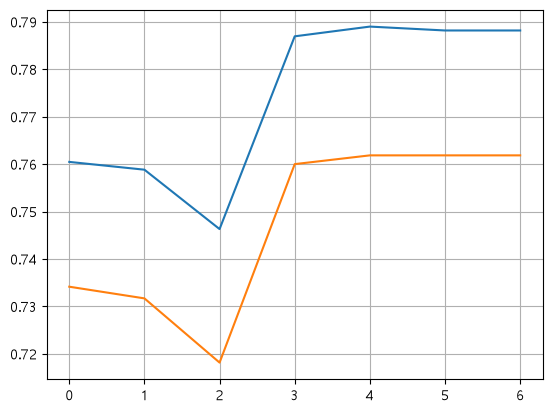

In [50]:
list1 = list(range(7))
plt.plot(list1, train_score)
plt.plot(list1, test_score)
plt.grid()
plt.show()

In [51]:
wmodel = make_pipeline(
    StandardScaler(),
    LogisticRegression(C=10, max_iter=1000),
)

In [52]:
wmodel.fit(train_data, train_label)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[float64](2,)","[0.,1.]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,3
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


In [53]:
print(f'파이프라인 학습 정확도: {wmodel.score(train_data, train_label)*100:.2f}%')
print(f'파이프라인 테스트 정확도: {wmodel.score(test_data, test_label)*100:.2f}%')


파이프라인 학습 정확도: 78.86%
파이프라인 테스트 정확도: 76.18%


In [54]:
joblib.dump(wmodel, 'wmodel.joblib')
print('모델 저장 완료')

모델 저장 완료
